In [79]:
import numpy as np
import pandas as pd

from scipy.stats import binom
from scipy.stats import bernoulli

In [80]:
n = 1
p = 0.5
size = 10

sample = np.random.binomial(n,p, size)

sample

array([1, 0, 1, 1, 0, 1, 1, 0, 1, 1])

In [81]:
X = bernoulli(0.5)
X

In [82]:
for x in range(size + 1):
    print(x, np.mean(sample == x))

0 0.3
1 0.7
2 0.0
3 0.0
4 0.0
5 0.0
6 0.0
7 0.0
8 0.0
9 0.0
10 0.0


In [83]:
print(np.mean(sample == X))
print(X.pmf(1))

print(X.mean())

0.0
0.5
0.5


In [84]:
import numpy as np
from scipy.stats import bernoulli

# Create Bernoulli distribution
X = bernoulli(0.5)

# Generate 10000 random observations
sample = X.rvs(size=10000)
print(sample)
# Empirical probabilities
print("Empirical P(X=0):", np.mean(sample == 0))
print("Empirical P(X=1):", np.mean(sample == 1))

# Theoretical probabilities
print("Theoretical P(X=0):", X.pmf(0))
print("Theoretical P(X=1):", X.pmf(1))

# Expected value
print("Mean:", X.mean())

# Variance
print("Variance:", X.var())

[1 1 1 ... 1 0 1]
Empirical P(X=0): 0.4969
Empirical P(X=1): 0.5031
Theoretical P(X=0): 0.5000000000000001
Theoretical P(X=1): 0.5
Mean: 0.5
Variance: 0.25


A company manufactures electronic bulbs. The probability that a bulb is defective is 0.10. A quality inspector randomly selects 10 bulbs.

Let \(X\) represent the number of defective bulbs.

Write Python code to:
1. Identify the distribution of \(X\), its parameters, and its possible values.
2. Simulate 10,000 inspections.
3. Calculate the empirical PMF for every possible value of \(X\).
4. Calculate the theoretical PMF using scipy.stats.
5. Plot the empirical and theoretical PMFs together.
6. Calculate empirical and theoretical expectation and variance.
7. Estimate \(P(X \geq 2)\) using simulation and calculate it theoretically.

In [85]:
p = 0.10
n = 10
# x = no of def bulbs

# 1. Dis = Binomial

from scipy.stats import binom
size = 10000
sample = np.random.binomial(n,p,size)

X = binom(n,p)

#Emprical
for x in range(n + 1):
    print(x, np.mean(sample == x))

0 0.3467
1 0.3914
2 0.1913
3 0.0557
4 0.0127
5 0.0019
6 0.0003
7 0.0
8 0.0
9 0.0
10 0.0


In [86]:
#Theoritical pmf
for x in range(n+1):
    print(x, X.pmf(x))

0 0.3486784401
1 0.38742048899999965
2 0.19371024450000007
3 0.05739562799999998
4 0.011160261000000006
5 0.0014880347999999997
6 0.00013778100000000004
7 8.748000000000003e-06
8 3.6449999999999996e-07
9 8.999999999999995e-09
10 1.0000000000000011e-10


In [87]:
# Empirical expectation and variance
print("Empirical Mean:", np.mean(sample))
print("Empirical Variance:", np.var(sample))

# Theoretical expectation and variance
print("Theoretical Mean:", X.mean())
print("Theoretical Variance:", X.var())

Empirical Mean: 1.0032
Empirical Variance: 0.9129897600000002
Theoretical Mean: 1.0
Theoretical Variance: 0.9


In [88]:
x2 = X.cdf(1)

print(1 - x2)

# Empirical probability
empirical = np.mean(sample >= 2)

# Theoretical probability
theoretical = 1 - X.cdf(1)

print("Empirical P(X >= 2):", empirical)
print("Theoretical P(X >= 2):", theoretical)

0.26390107090000015
Empirical P(X >= 2): 0.2619
Theoretical P(X >= 2): 0.26390107090000015



Threshold: 0.65
TN: 882 FP: 18 FN: 30 TP: 70
Sensitivity: 0.7
Specificity: 0.98
Precision: 0.7954545454545454

Threshold: 0.4
TN: 679 FP: 221 FN: 4 TP: 96
Sensitivity: 0.96
Specificity: 0.7544444444444445
Precision: 0.3028391167192429

ROC AUC: 0.9631888888888889
Average Precision: 0.832551520349605
Prevalence: 0.1


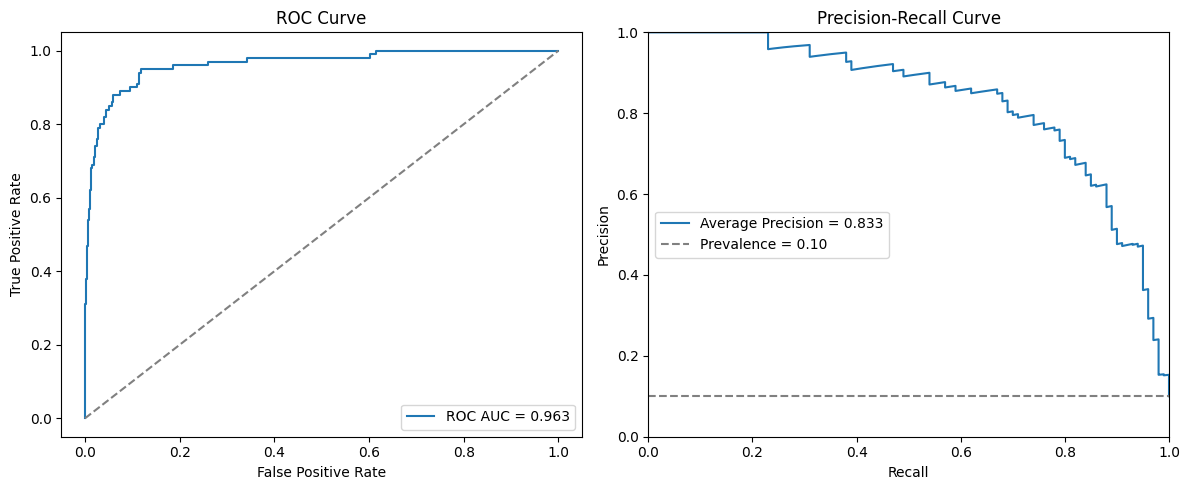

In [89]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

# Generate data (Do not modify)
rng = np.random.default_rng(42)

fraud_scores = rng.beta(5, 2, size=100)
genuine_scores = rng.beta(2, 5, size=900)

y_true = np.r_[
    np.ones(100, dtype=int),
    np.zeros(900, dtype=int)
]

scores = np.r_[fraud_scores, genuine_scores]


# Evaluate threshold
def evaluate_threshold(threshold):

    # A. Convert scores into predicted classes
    y_pred = (scores >= threshold).astype(int)

    # B. Obtain TN, FP, FN and TP
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0,1]).ravel()

    # C. Calculate sensitivity
    sensitivity = tp / (tp + fn)

    # D. Calculate specificity
    specificity = tn / (tn + fp)

    # E. Calculate precision
    precision = tp / (tp + fp)

    print("\nThreshold:", threshold)
    print("TN:", tn, "FP:", fp, "FN:", fn, "TP:", tp)
    print("Sensitivity:", sensitivity)
    print("Specificity:", specificity)
    print("Precision:", precision)


# Evaluate both thresholds
evaluate_threshold(0.65)
evaluate_threshold(0.40)


# F. Calculate ROC curve values
fpr, tpr, threshold = roc_curve(y_true, scores )


# G. Calculate Precision-Recall curve values
pr_precision, pr_recall, threshold = precision_recall_curve(y_true, scores)


# H. Calculate ROC AUC, Average Precision and Prevalence
roc_auc = roc_auc_score(y_true, scores)
avg_precision = average_precision_score(y_true, scores)
prevalence = np.mean(y_true)


print("\nROC AUC:", roc_auc)
print("Average Precision:", avg_precision)
print("Prevalence:", prevalence)


# Plot both curves
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC Curve
axes[0].plot(fpr, tpr, label=f"ROC AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set(
    title="ROC Curve",
    xlabel="False Positive Rate",
    ylabel="True Positive Rate"
)
axes[0].legend()

# Precision-Recall Curve
axes[1].plot(
    pr_recall,
    pr_precision,
    label=f"Average Precision = {avg_precision:.3f}"
)

axes[1].axhline(
    prevalence,
    linestyle="--",
    color="gray",
    label=f"Prevalence = {prevalence:.2f}"
)

axes[1].set(
    title="Precision-Recall Curve",
    xlabel="Recall",
    ylabel="Precision",
    xlim=(0, 1),
    ylim=(0, 1)
)
axes[1].legend()

plt.tight_layout()
plt.show()

# Question 1: Fraud Detection System

A fraud detection system processes transactions. Assume that 8% of transactions are fraudulent. It flags 85% of fraudulent transactions and incorrectly flags 10% of genuine transactions.

Write Python code to:

1. Simulate 10,000 independent transactions, storing the true fraud status and the system’s flag for each transaction.
2. Construct a table showing the number of fraudulent and genuine transactions that were flagged and not flagged.
3. Estimate the relevant probabilities from the simulation: the probability of a transaction being flagged, the probability of a flag given fraud, and the probability of fraud given a flag.
4. Calculate the theoretical probability of a flag using the law of total probability and the theoretical probability of fraud given a flag using Bayes’ rule. Compare these with the simulated estimates.


# Question 2: Server Request Failures — Binomial Distribution

A monitoring system checks 12 independent server requests during each minute. Each request has a 0.20 probability of failing. Let \(X\) be the number of failed requests in one minute.

Write Python code to:

1. Identify the distribution of \(X\), its parameters, and its possible values.
2. Simulate 20,000 minutes and calculate the empirical PMF for every possible value of \(X\).
3. Calculate the theoretical PMF and plot it alongside the empirical PMF.
4. Calculate the empirical and theoretical expectation and variance. Present the four values in a table.
5. Estimate \(P(X \geq 4)\) from the simulation and calculate it theoretically.


In [90]:
# x = no of failed req.

p = 0.20
n = 12

size = 20000

# 1. Binomial

sample = np.random.binomial(n,p,size)
X = binom(n,p)

sample.size

for x in range(n + 1):
    print(x, round(np.mean(sample == x),4))

#empirical
print("empirical means:" ,np.mean(sample))
print("empirical var:",np.var(sample))

#therotical
print(X.mean())
print(X.var())


x4 = X.cdf(3)
prob = 1 - x4
print("X>= 4 :", prob)




0 0.0692
1 0.211
2 0.2812
3 0.2334
4 0.1348
5 0.0498
6 0.0174
7 0.0028
8 0.0005
9 0.0
10 0.0
11 0.0
12 0.0
empirical means: 2.38945
empirical var: 1.9240786974999995
2.4000000000000004
1.9200000000000004
X>= 4 : 0.2054310502400003


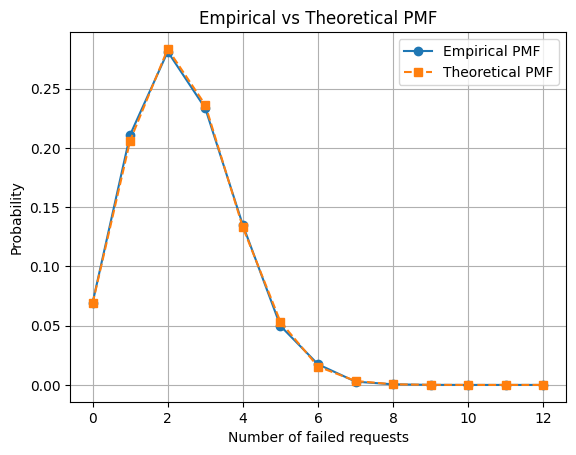

In [91]:
import matplotlib.pyplot as plt

empirical = []
theoretical = []

for x in range(n + 1):
    empirical.append(np.mean(sample == x))
    theoretical.append(X.pmf(x))

plt.plot(range(n + 1), empirical, 'o-', label="Empirical PMF")
plt.plot(range(n + 1), theoretical, 's--', label="Theoretical PMF")

plt.xlabel("Number of failed requests")
plt.ylabel("Probability")
plt.title("Empirical vs Theoretical PMF")
plt.legend()
plt.grid()
plt.show()

In [179]:
import numpy as np
from scipy.stats import poisson

# Average rate
lam = 4

# Create Poisson distribution
X = poisson(mu=lam)

# Generate 10 random values
sample = np.random.randint(0,2,10)

print("Random samples:", sample)

# PMF
for x in range(10):
    print(x, X.pmf(x))

# Mean and variance
print("Mean:", X.mean())
print("Variance:", X.var())

Random samples: [0 1 0 1 0 1 1 1 1 0]
0 0.01831563888873418
1 0.07326255555493673
2 0.14652511110987343
3 0.19536681481316454
4 0.19536681481316454
5 0.1562934518505317
6 0.10419563456702102
7 0.0595403626097263
8 0.029770181304863145
9 0.013231191691050305
Mean: 4.0
Variance: 4.0


A medical test is used to detect a disease.
- 10% of people have the disease.
- If a person has the disease, the test gives a positive result 90% of the time.
- If a person does not have the disease, the test still gives a positive result 5% of the time.
Question: If a randomly selected person tests positive, what is the probability that the person actually has the disease?

In [96]:
p_disease = 0.10
tp = 0.90 #P(predicted pos | actual pos)
fp = 0.05 #P(pred pos | actual neg)

# P(actual pos | predicted pos)

P_find = (0.90 * 0.10) / ((0.90 * 0.10) + (0.05 * 0.90)) 

print(P_find * 100)



66.66666666666667


In [97]:
# Import libraries
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

# Dataset
X = np.array([
    [20, 50000],
    [25, 60000],
    [30, 70000],
    [35, 80000],
    [40, 90000],
    [22, 25000],
    [27, 30000],
    [32, 35000],
    [37, 40000],
    [42, 45000]
])

# Target: 1 = Buy, 0 = Not Buy
y = np.array([1, 1, 1, 1, 1, 0, 0, 0, 0, 0])

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Create Naive Bayes model
model = GaussianNB()

# Train model
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Results
print("Actual values:", y_test)
print("Predicted values:", y_pred)

# Accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Confusion Matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Classification Report
print(classification_report(y_test, y_pred))

Actual values: [0 1 0]
Predicted values: [0 1 0]
Accuracy: 1.0
Confusion Matrix:
[[2 0]
 [0 1]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         1

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3



In [107]:
y = np.random.randint(0, 2, size=10)
print(y)

[1 0 1 0 0 0 0 1 0 0]


In [ ]:
# x = []
# for i in range(10):
#     X = np.array(
#     [
#     [np.random.randint(10)], 
#     [np.random.randint(10)]
#     ])
#     x.append(X)

# print(x)

[array([[4],
       [9]]), array([[4],
       [0]]), array([[5],
       [1]]), array([[6],
       [0]]), array([[3],
       [6]]), array([[4],
       [7]]), array([[5],
       [3]]), array([[5],
       [7]]), array([[8],
       [2]]), array([[5],
       [6]])]
